# 20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed: benchmark



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "benchmark" / "by_family" / '20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.583749,0.104799,15
1,DAGMA_Linear,0.297902,0.125217,15
2,DAGMA_Nonlinear,0.364061,0.040671,15
3,DAS,0.456641,0.112567,15
4,DirectLiNGAM,0.306594,0.084000,15
5,FCI,0.166515,0.096268,15
6,GES,0.434051,0.143125,15
7,GOLEM,0.317772,0.150289,15
8,GRaSP,0.437429,0.110207,15
9,GraNDAG,0.138309,0.154783,15


,model,mean,std,size
0,AVICI,21.666667,6.410557,15
1,DAGMA_Linear,25.400000,4.968472,15
2,DAGMA_Nonlinear,25.200000,2.455315,15
3,DAS,30.933333,7.215724,15
4,DirectLiNGAM,37.600000,6.822233,15
5,FCI,31.466667,6.501282,15
6,GES,30.066667,6.922702,15
7,GOLEM,29.600000,7.641989,15
8,GRaSP,26.511111,5.200163,15
9,GraNDAG,26.800000,3.098387,15


,model,mean,std,size
0,AVICI,0.601844,0.118098,15
1,DAGMA_Linear,0.389026,0.149065,15
2,DAGMA_Nonlinear,0.421004,0.045562,15
3,DAS,0.386906,0.107395,15
4,DirectLiNGAM,0.253698,0.071177,15
5,FCI,0.486809,0.290764,15
6,GES,0.421379,0.146195,15
7,GOLEM,0.370434,0.192622,15
8,GRaSP,0.523779,0.117999,15
9,GraNDAG,0.541282,0.432552,15


,model,mean,std,size
0,AVICI,0.578773,0.118910,15
1,DAGMA_Linear,0.245926,0.115467,15
2,DAGMA_Nonlinear,0.325881,0.052106,15
3,DAS,0.561543,0.119628,15
4,DirectLiNGAM,0.390813,0.111183,15
5,FCI,0.102797,0.061452,15
6,GES,0.453867,0.153310,15
7,GOLEM,0.288168,0.140084,15
8,GRaSP,0.379022,0.104848,15
9,GraNDAG,0.085786,0.106612,15


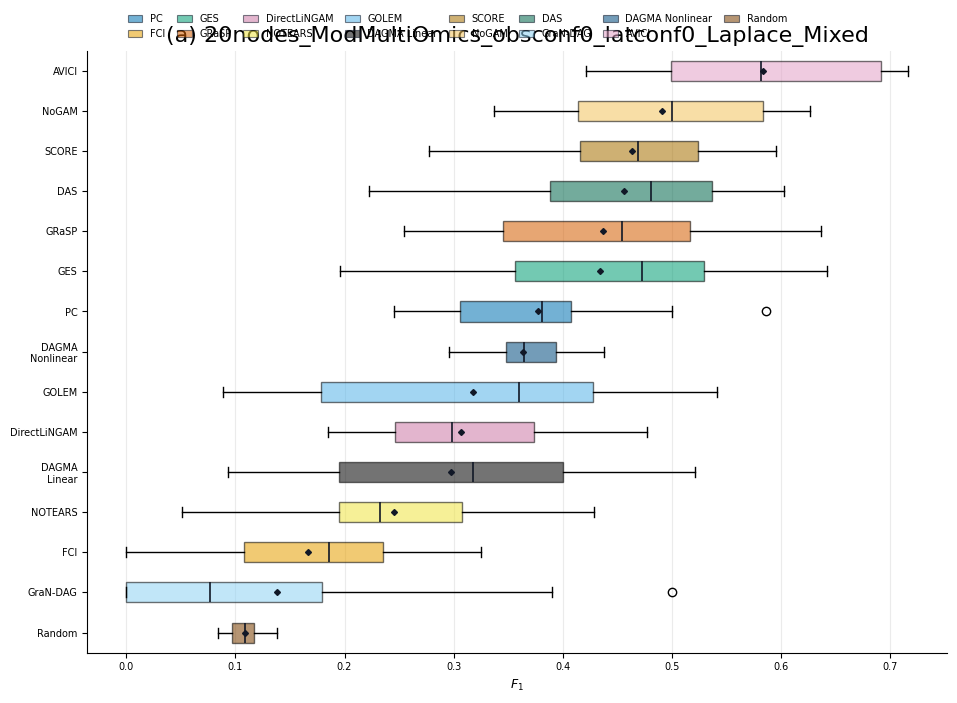

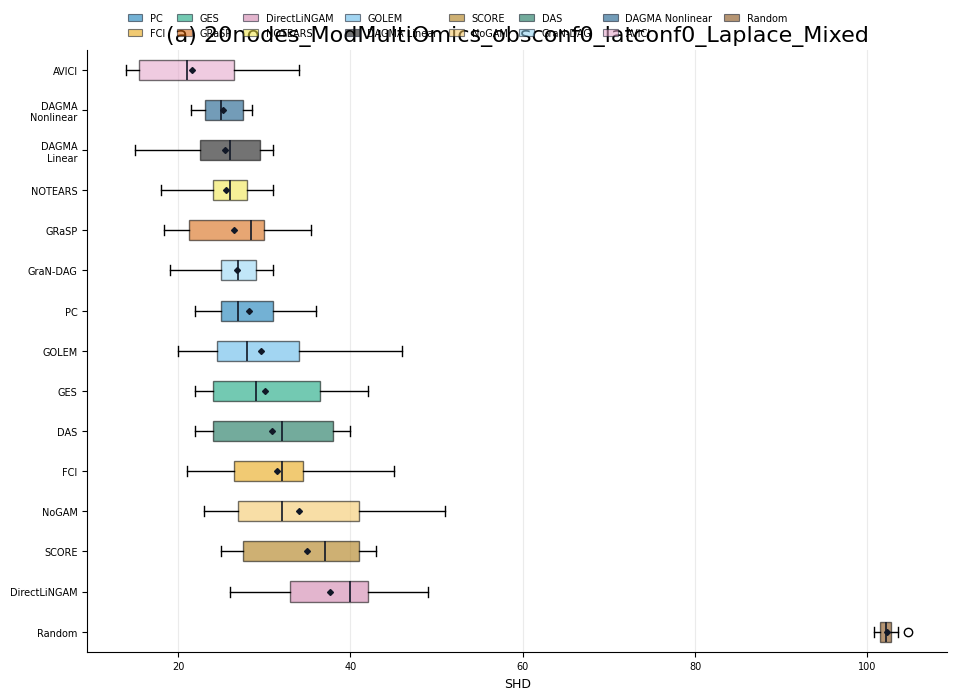

,dataset_seed,model,f1_range
0,13,AVICI,0.000000
1,13,DAGMA_Linear,0.000000
2,13,DAGMA_Nonlinear,0.452242
3,13,DAS,0.000000
4,13,DirectLiNGAM,0.000000
5,13,FCI,0.000000
6,13,GES,0.000000
7,13,GOLEM,0.000000
8,13,GRaSP,0.387518
9,13,GraNDAG,0.000000


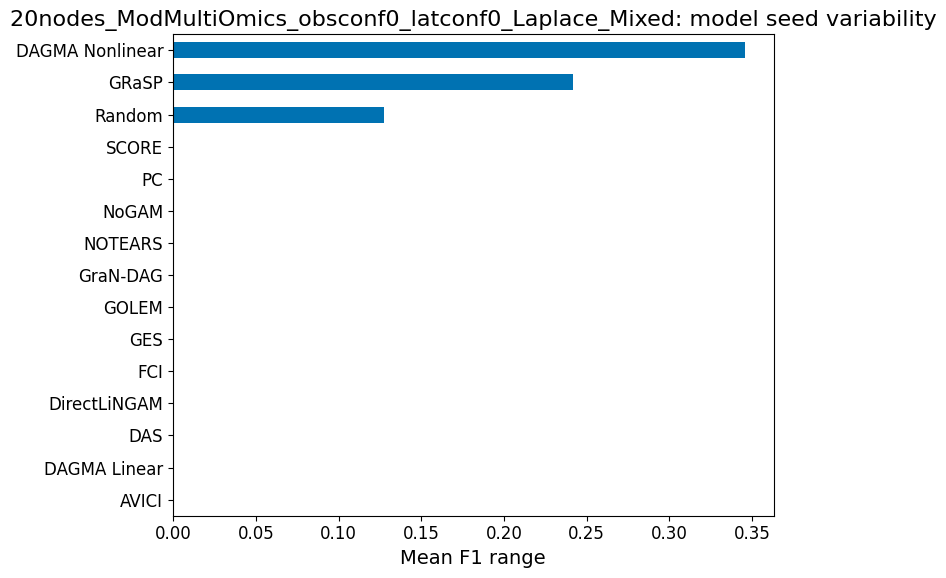

,model_seed,model,f1_range
0,0,AVICI,0.295929
1,0,DAGMA_Linear,0.428716
2,0,DAGMA_Nonlinear,0.367938
3,0,DAS,0.380518
4,0,DirectLiNGAM,0.292997
5,0,FCI,0.325581
6,0,GES,0.446779
7,0,GOLEM,0.452778
8,0,GRaSP,0.462865
9,0,GraNDAG,0.500000


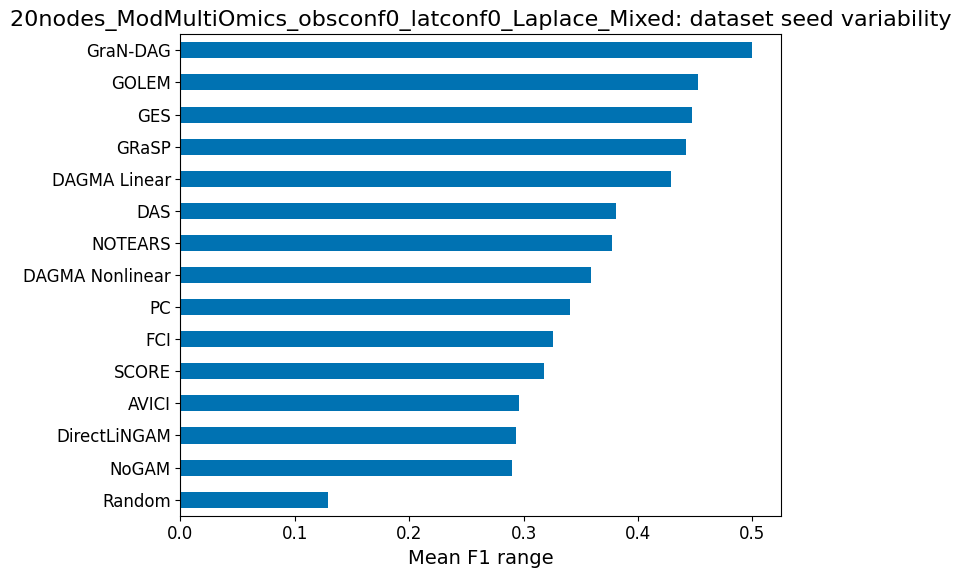

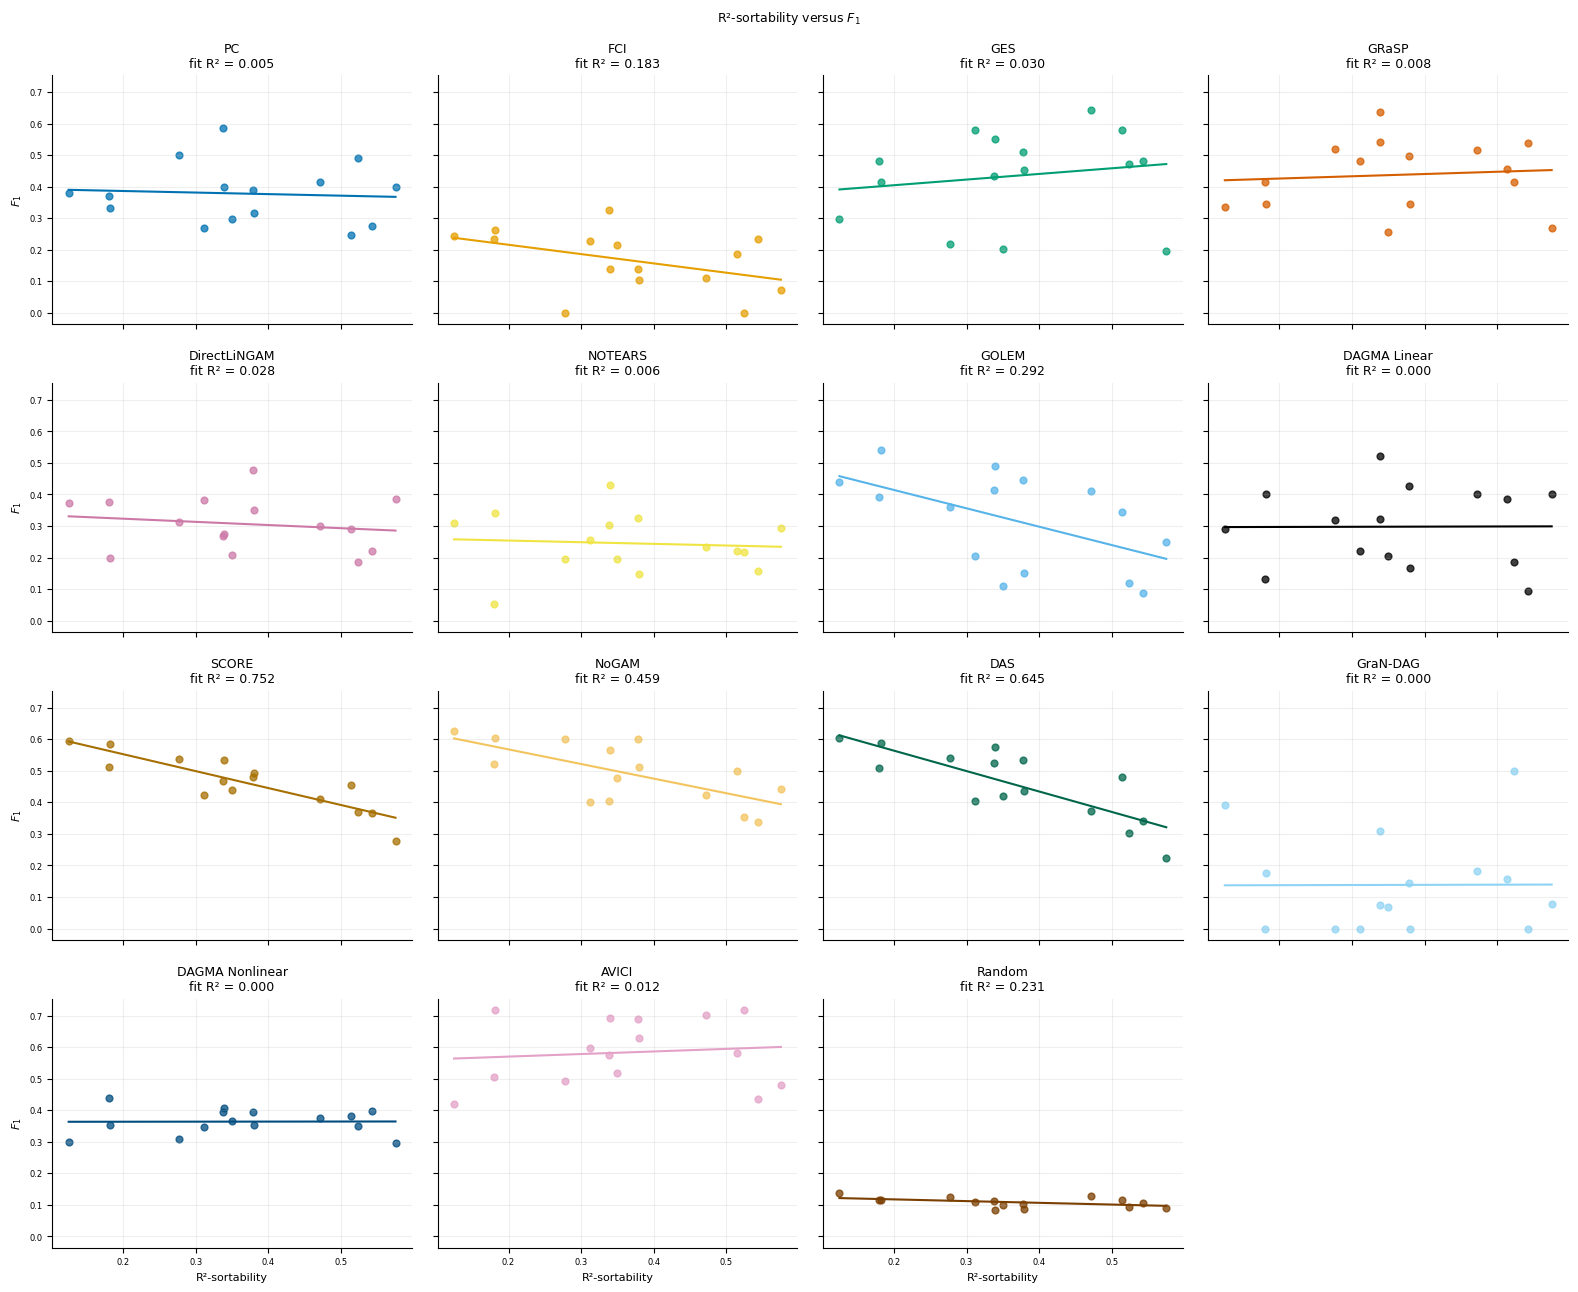

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,AVICI,0.629630,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
1,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Linear,0.166667,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
2,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Nonlinear,0.353110,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
3,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAS,0.434783,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
4,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DirectLiNGAM,0.351351,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
5,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,FCI,0.105263,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
6,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GES,0.451613,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
7,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GOLEM,0.150943,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
8,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GRaSP,0.345273,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
9,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GraNDAG,0.000000,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,13,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
1,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,21,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.267606,0.338028,71,19,0,24,0,20,2000
2,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,29,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.611111,0.513889,72,44,0,37,0,20,2000
3,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,32,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.261364,0.181818,88,23,0,16,0,20,2000
4,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,44,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.204819,0.277108,83,17,0,23,0,20,2000
5,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,47,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.611650,0.349515,103,63,0,36,0,20,2000
6,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,52,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.125000,0.125000,80,10,0,10,0,20,2000
7,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,71,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.553571,0.339286,56,31,0,19,0,20,2000
8,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,75,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.415584,0.311688,77,32,0,24,0,20,2000
9,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,102,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.547619,0.523810,42,23,0,22,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.108627,0.011800,0.081602,0.553895,0.699975,0.103664,0.713133
1,DAGMA_Linear,15,0.005657,0.000032,0.005078,0.296045,0.984037,0.007169,0.979772
2,DAGMA_Nonlinear,15,0.006997,0.000049,0.002040,0.363315,0.980255,-0.003571,0.989921
3,DAS,15,-0.802874,0.644607,-0.647842,0.693652,0.000314,-0.789286,0.000467
4,DirectLiNGAM,15,-0.166820,0.027829,-0.100446,0.343342,0.552360,-0.128571,0.647916
5,FCI,15,-0.427934,0.183128,-0.295304,0.274551,0.111550,-0.513878,0.050052
6,GES,15,0.174508,0.030453,0.179036,0.368551,0.533919,0.126899,0.652228
7,GOLEM,15,-0.540809,0.292475,-0.582614,0.530919,0.037376,-0.550000,0.033655
8,GRaSP,15,0.090725,0.008231,0.071672,0.411208,0.747788,-0.007143,0.979844
9,GraNDAG,15,0.004631,0.000021,0.005139,0.136429,0.986930,0.054554,0.846880


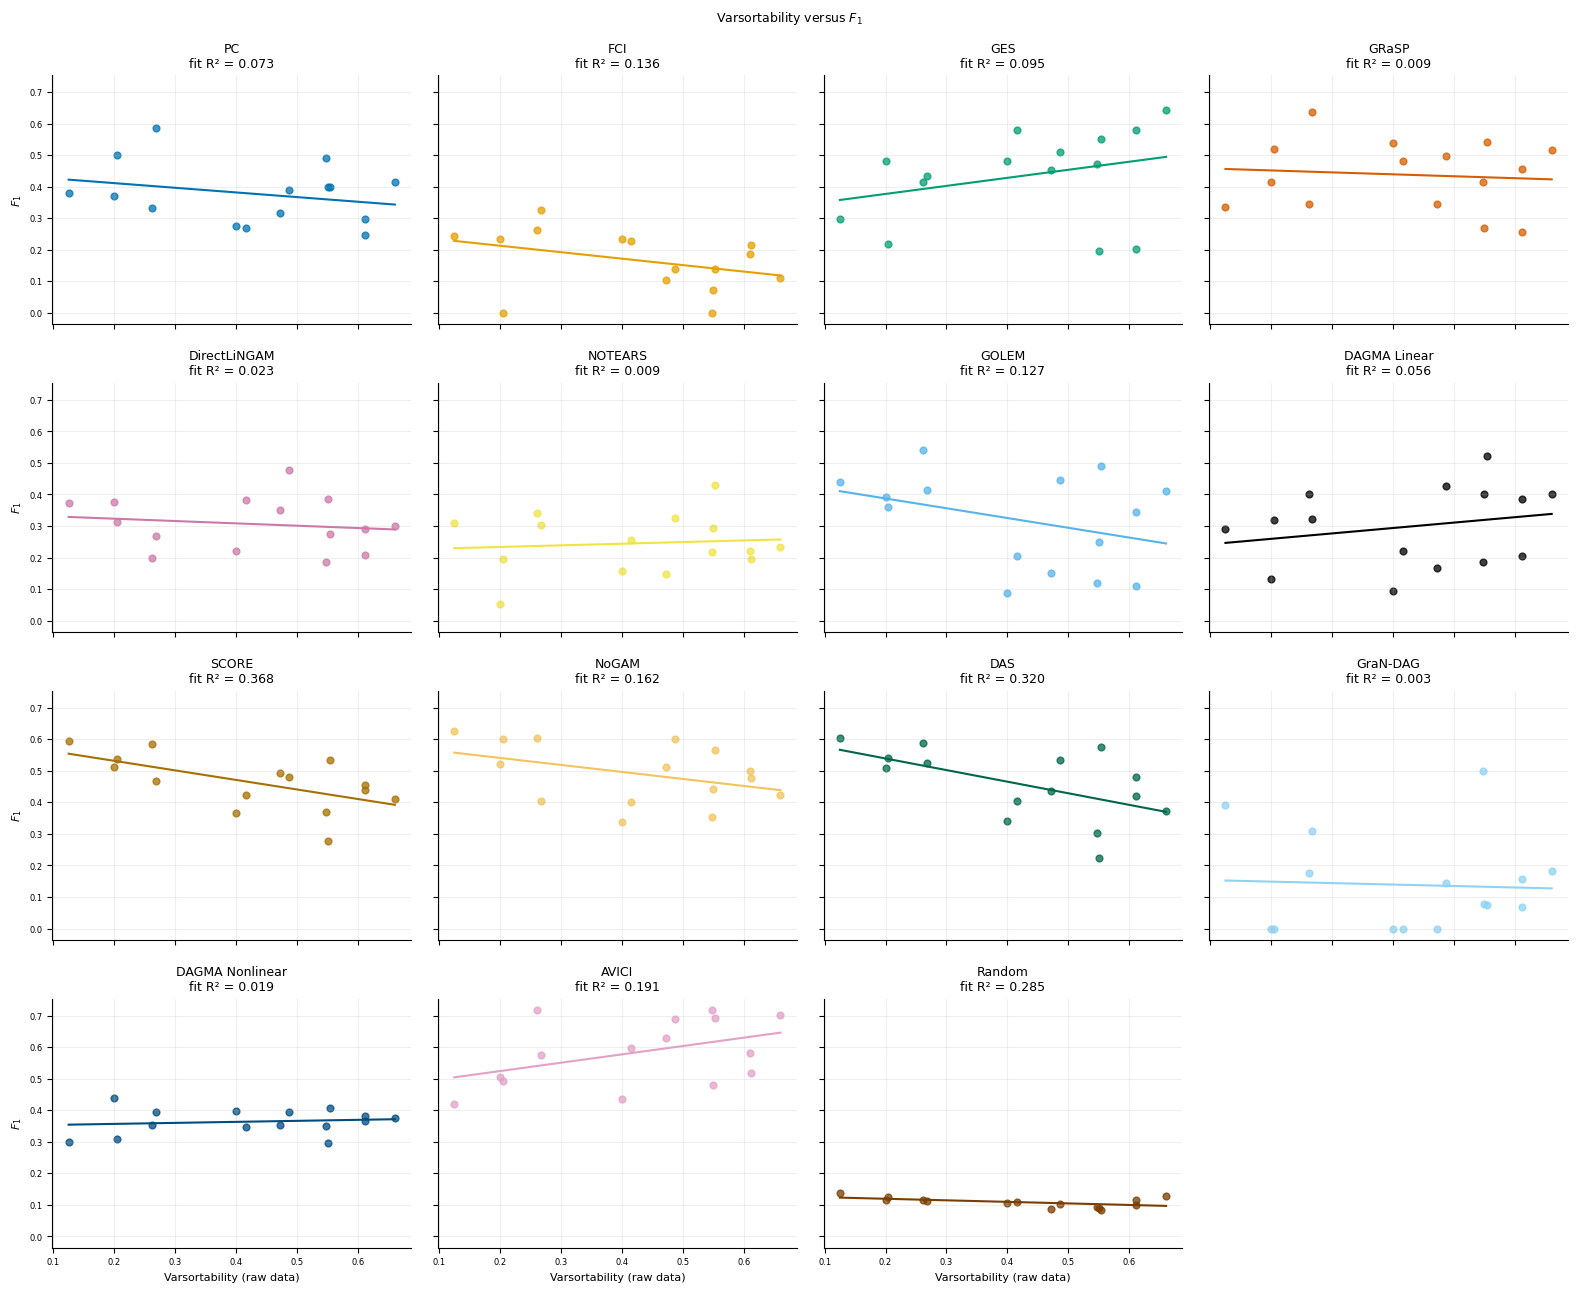

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,AVICI,0.629630,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
1,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Linear,0.166667,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
2,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Nonlinear,0.353110,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
3,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAS,0.434783,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
4,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DirectLiNGAM,0.351351,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
5,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,FCI,0.105263,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
6,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GES,0.451613,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
7,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GOLEM,0.150943,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
8,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GRaSP,0.345273,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
9,13,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GraNDAG,0.000000,15,20,ModMultiOmics,0,0,Laplace,...,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,13,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.472222,0.379630,108,51,0,41,0,20,2000
1,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,21,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.267606,0.338028,71,19,0,24,0,20,2000
2,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,29,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.611111,0.513889,72,44,0,37,0,20,2000
3,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,32,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.261364,0.181818,88,23,0,16,0,20,2000
4,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,44,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.204819,0.277108,83,17,0,23,0,20,2000
5,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,47,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.611650,0.349515,103,63,0,36,0,20,2000
6,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,52,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.125000,0.125000,80,10,0,10,0,20,2000
7,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,71,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.553571,0.339286,56,31,0,19,0,20,2000
8,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,75,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.415584,0.311688,77,32,0,24,0,20,2000
9,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,102,benchmark,True,datasets/benchmark/20nodes_ModMultiOmics_obsco...,0.547619,0.523810,42,23,0,22,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.437325,0.191253,0.264781,0.471351,0.103073,0.411081,0.127954
1,DAGMA_Linear,15,0.237259,0.056292,0.171637,0.225043,0.394527,0.351257,0.199222
2,DAGMA_Nonlinear,15,0.137321,0.018857,0.032266,0.350365,0.625533,0.100000,0.722897
3,DAS,15,-0.565450,0.319734,-0.367734,0.612742,0.028036,-0.507143,0.053664
4,DirectLiNGAM,15,-0.152720,0.023323,-0.074114,0.338055,0.586873,-0.164286,0.558497
5,FCI,15,-0.368394,0.135714,-0.204891,0.253490,0.176662,-0.458372,0.085726
6,GES,15,0.308765,0.095336,0.255311,0.325672,0.262827,0.321716,0.242274
7,GOLEM,15,-0.356931,0.127400,-0.309912,0.449328,0.191557,-0.242857,0.383128
8,GRaSP,15,-0.096558,0.009323,-0.061479,0.463526,0.732105,-0.057143,0.839700
9,GraNDAG,15,-0.051914,0.002695,-0.046423,0.158016,0.854217,0.138205,0.623288


In [3]:
for study, frame in [("benchmark", main)]:
    frame = frame.loc[frame.dataset.eq('20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,AVICI,r2_sortability,15,0.103664,0.713133,estimated,1.000000
1,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Linear,r2_sortability,15,0.007169,0.979772,estimated,1.000000
2,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAGMA_Nonlinear,r2_sortability,15,-0.003571,0.989921,estimated,1.000000
3,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DAS,r2_sortability,15,-0.789286,0.000467,estimated,0.006543
4,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,DirectLiNGAM,r2_sortability,15,-0.128571,0.647916,estimated,1.000000
5,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,FCI,r2_sortability,15,-0.513878,0.050052,estimated,0.550570
6,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GES,r2_sortability,15,0.126899,0.652228,estimated,1.000000
7,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GOLEM,r2_sortability,15,-0.550000,0.033655,estimated,0.403864
8,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GRaSP,r2_sortability,15,-0.007143,0.979844,estimated,1.000000
9,benchmark,untuned,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,GraNDAG,r2_sortability,15,0.054554,0.846880,estimated,1.000000
